# Tarea 01: Aproximación de una función desconocida

Generamos datos con una función que **nosotros definimos y ustedes no conocen**. Su
trabajo es reconstruirla a partir de los datos.

No es un acertijo: es lo que hace el machine learning todos los días. El capítulo 02
plantea el aprendizaje como **aproximación de funciones**, y aquí van a hacer
exactamente eso, con la ventaja rara de que existe una respuesta correcta y un límite
teórico al que se puede llegar.

## Lo que hay

- `train.csv`: 800 observaciones con 12 variables (`x1` a `x12`) y la respuesta `y`.
- `test.csv`: 400 observaciones con las mismas 12 variables, **sin** `y`.

Entregan sus 400 predicciones y un bot las califica automáticamente.

## Cómo se califica

| Su MSE en el conjunto de prueba | Calificación |
|---|---|
| Igual o peor que una regresión lineal con las 12 variables crudas | **5.0** |
| Igual al modelo bien especificado (el error irreducible) | **10.0** |
| En medio | proporcional a la mejora |

**El 5 está garantizado si entregan algo que corre.** El código del baseline se lo damos
hecho más abajo; de ahí para arriba es mérito suyo.

Tienen **3 intentos** de calificación. Un comentario `/validar` revisa el formato y les
dice cuál es su MSE objetivo **sin gastar intento**, así que úsenlo antes del primero.

## Qué se evalúa además del MSE

El MSE es la mitad. La otra mitad es la **Parte 5: la bitácora**, donde documentan cada
hipótesis que probaron — incluidas las que fallaron. Un notebook con buen MSE y bitácora
vacía vale poco: significa que no entendieron por qué funcionó.

---

## Las reglas sobre la IA

**Sí pueden usar IA. De hecho quiero que la usen.** Pero de una forma específica.

La IA no puede ver sus datos. Puede explicarles teoría, listarles técnicas o decirles qué
función de `matplotlib` usar. Lo que **no** puede hacer es mirar una gráfica de residuales
y decirles qué término falta, porque eso solo lo revela correr el código con *sus* datos, y
cada quien tiene datos distintos.

Así que la IA es su tutor, no su chofer. Para que sea tutor, péguenle esto al inicio de
cada conversación:

> Eres mi tutor de regresión, no mi resolvedor. Reglas: (1) no escribes código que yo
> pueda copiar; si te pido código, me devuelves el nombre de la función y su docstring.
> (2) No me das la respuesta: me preguntas qué espero ver y por qué. (3) Cuando me
> equivoque, no me corriges: me sugieres qué gráfica revelaría mi error. (4) Máximo
> tres oraciones por respuesta.

Y una regla para ustedes: **si la IA les da código y no pueden explicar qué hace línea
por línea, bórrenlo y escríbanlo ustedes.** Se nota en la bitácora, y se nota más en el
examen.

---
## Parte 0. Su variante

Cada quien tiene **datos distintos**: las 12 variables juegan papeles diferentes según
la persona. Copiar las predicciones de alguien más da un MSE malísimo. Comparar
*métodos* entre ustedes, en cambio, es buena idea y se los recomiendo.

Su carpeta de datos se identifica con su **clave única del ITAM**.

In [2]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110
SEMILLA = 42

In [3]:
# TODO: pongan su clave única del ITAM (con o sin ceros a la izquierda, da lo mismo)
CLAVE_UNICA = "205654"

# De la clave sale el nombre de su carpeta. No lo cambien a mano.
_clave = "".join(c for c in CLAVE_UNICA if c.isdigit()).zfill(9)
CARPETA = "v" + hashlib.sha256(_clave.encode()).hexdigest()[:8]

# Funciona corriendo el notebook desde `tareas/` o desde la raíz del repo
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tareas/tarea_01_datos").exists())
MIS_DATOS = RAIZ / "tareas/tarea_01_datos" / CARPETA

assert CLAVE_UNICA, "Escriban su clave única en CLAVE_UNICA."
assert MIS_DATOS.exists(), (
    f"No existe la carpeta {CARPETA}. Revisen su clave única: si está mal escrita, "
    f"el nombre de la carpeta sale distinto y no van a encontrar sus datos."
)

train = pd.read_csv(MIS_DATOS / "train.csv")
test = pd.read_csv(MIS_DATOS / "test.csv")

VARIABLES = [f"x{i}" for i in range(1, 13)]
print(f"Su variante: {CARPETA}")
print(f"train: {train.shape}   test: {test.shape}")
train.head()

Su variante: vdd692efc
train: (800, 13)   test: (400, 12)


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,y
0,-0.158439,0.281534,2.678609,-0.318256,-1.638122,2.911188,0.441112,-1.329821,0.382228,2.055634,3.512119,84.628271,8.653856
1,-0.060251,-0.142111,0.599478,0.299893,-1.887027,-1.842135,0.632390,-0.541273,0.060819,1.081418,0.147274,86.092716,7.850352
2,0.023078,-0.645241,2.507492,-0.140518,1.187332,1.984703,2.219909,0.225973,1.760022,0.498585,1.758152,56.466271,4.797511
3,-0.117543,0.614731,-2.454597,-0.357983,1.172058,-2.660273,2.102785,0.836012,-0.955273,15.262085,1.122356,60.340336,28.055699
4,0.446281,-0.191211,0.466663,0.291849,-0.073228,1.812737,2.410873,1.313824,-0.132616,0.366464,2.222893,33.103483,13.975004


In [4]:
# TODO: primer vistazo. ¿Qué rangos tienen las variables? ¿Hay faltantes?
train.describe().T

,count,mean,std,min,25%,50%,75%,max
x1,800.0,-0.014511,0.288870,-0.499358,-0.265689,-0.035657,0.226017,0.496732
x2,800.0,-0.013470,0.984235,-2.986818,-0.709166,-0.036728,0.645400,3.197908
x3,800.0,-0.044255,1.773937,-2.991674,-1.616637,-0.107368,1.530112,2.986118
x4,800.0,0.018222,0.291391,-0.498147,-0.238600,0.027839,0.284328,0.499706
x5,800.0,0.025938,1.133211,-1.983551,-0.926435,0.057458,0.981072,1.996876
x6,800.0,-0.022896,1.748402,-2.991181,-1.470311,-0.130978,1.557385,2.998934
x7,800.0,1.719598,2.099277,0.023897,0.558590,1.064860,2.121484,22.519925
x8,800.0,0.001199,1.174647,-1.991277,-1.050546,-0.029429,1.061472,1.993967
x9,800.0,-0.000680,0.978195,-2.733788,-0.608380,-0.044019,0.673815,3.653841
x10,800.0,1.714658,2.201558,0.035529,0.529233,1.022642,1.982261,27.811353


### 0.1 El baseline que hay que ganar

Este es el modelo de referencia: una regresión lineal con las 12 variables **tal como
vienen**, sin transformar nada. Su MSE sobre el conjunto de prueba es, por definición, la
calificación **5.0**.

Se lo damos corrido para que arranquen sabiendo exactamente qué hay que superar.

In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    train[VARIABLES], train["y"], test_size=0.25, random_state=SEMILLA
)

baseline = LinearRegression().fit(X_train, y_train)
mse_baseline = mean_squared_error(y_val, baseline.predict(X_val))

print(f"MSE del baseline en validación: {mse_baseline:.2f}")
print(f"R² del baseline en validación : {baseline.score(X_val, y_val):.3f}")
print(f"\nDesviación estándar de y: {train['y'].std():.2f}")

MSE del baseline en validación: 141.23
R² del baseline en validación : 0.300

Desviación estándar de y: 14.50


### 0.2 Cómo medir su progreso sin gastar intentos

Solo tienen 3 calificaciones, y necesitan medirse muchas más veces que eso. La solución
es la de siempre: **partir `train` en entrenamiento y validación**, ajustar en una parte
y medir en la otra. Eso ya lo hicimos en la celda anterior.

Dos advertencias importantes:

- Su MSE de validación **no** va a coincidir exactamente con el oficial. El oficial se
  mide sobre `test.csv`, que son otras 400 observaciones. Su número es una *estimación*
  del oficial, con su propia incertidumbre.
- Si eligen entre muchos modelos usando el mismo conjunto de validación, van a
  sobreajustar la validación. Para decisiones finas, usen validación cruzada
  (`cross_val_score`) en lugar de una sola partición.

**Nunca** ajusten nada usando `test.csv`: no tiene `y`, así que ni podrían — y ese es
justo el punto.

---
## Parte 1. Exploración

Antes de modelar, mírenlos. El objetivo de esta parte **no** es encontrar la respuesta,
es formarse sospechas que después van a confirmar o descartar.

Tres cosas que vale la pena graficar:

1. La distribución de cada variable por separado.
2. `y` contra cada variable, una gráfica por variable.
3. La matriz de correlación.

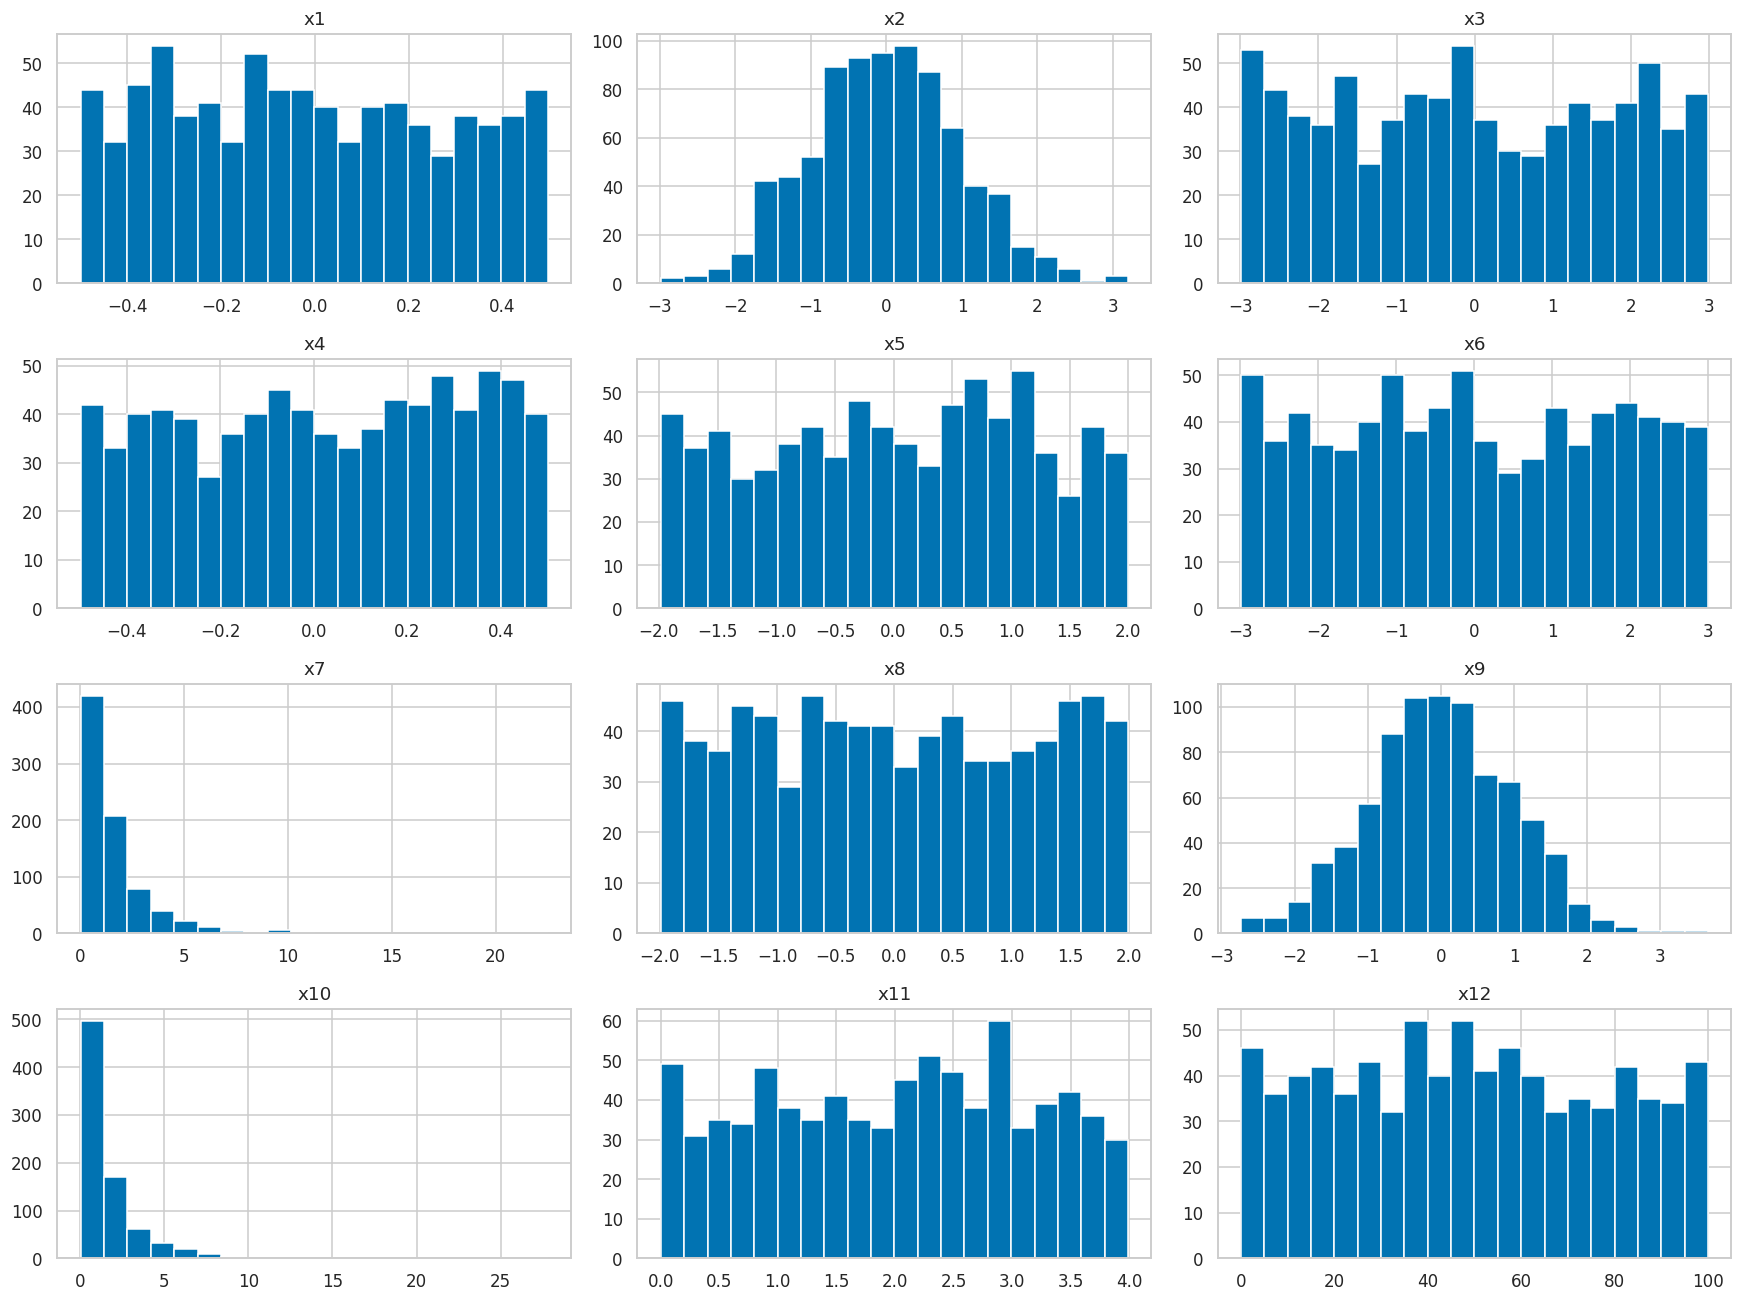

In [6]:
train[VARIABLES].hist(bins=20, figsize=(16, 12))
plt.tight_layout()
plt.show()

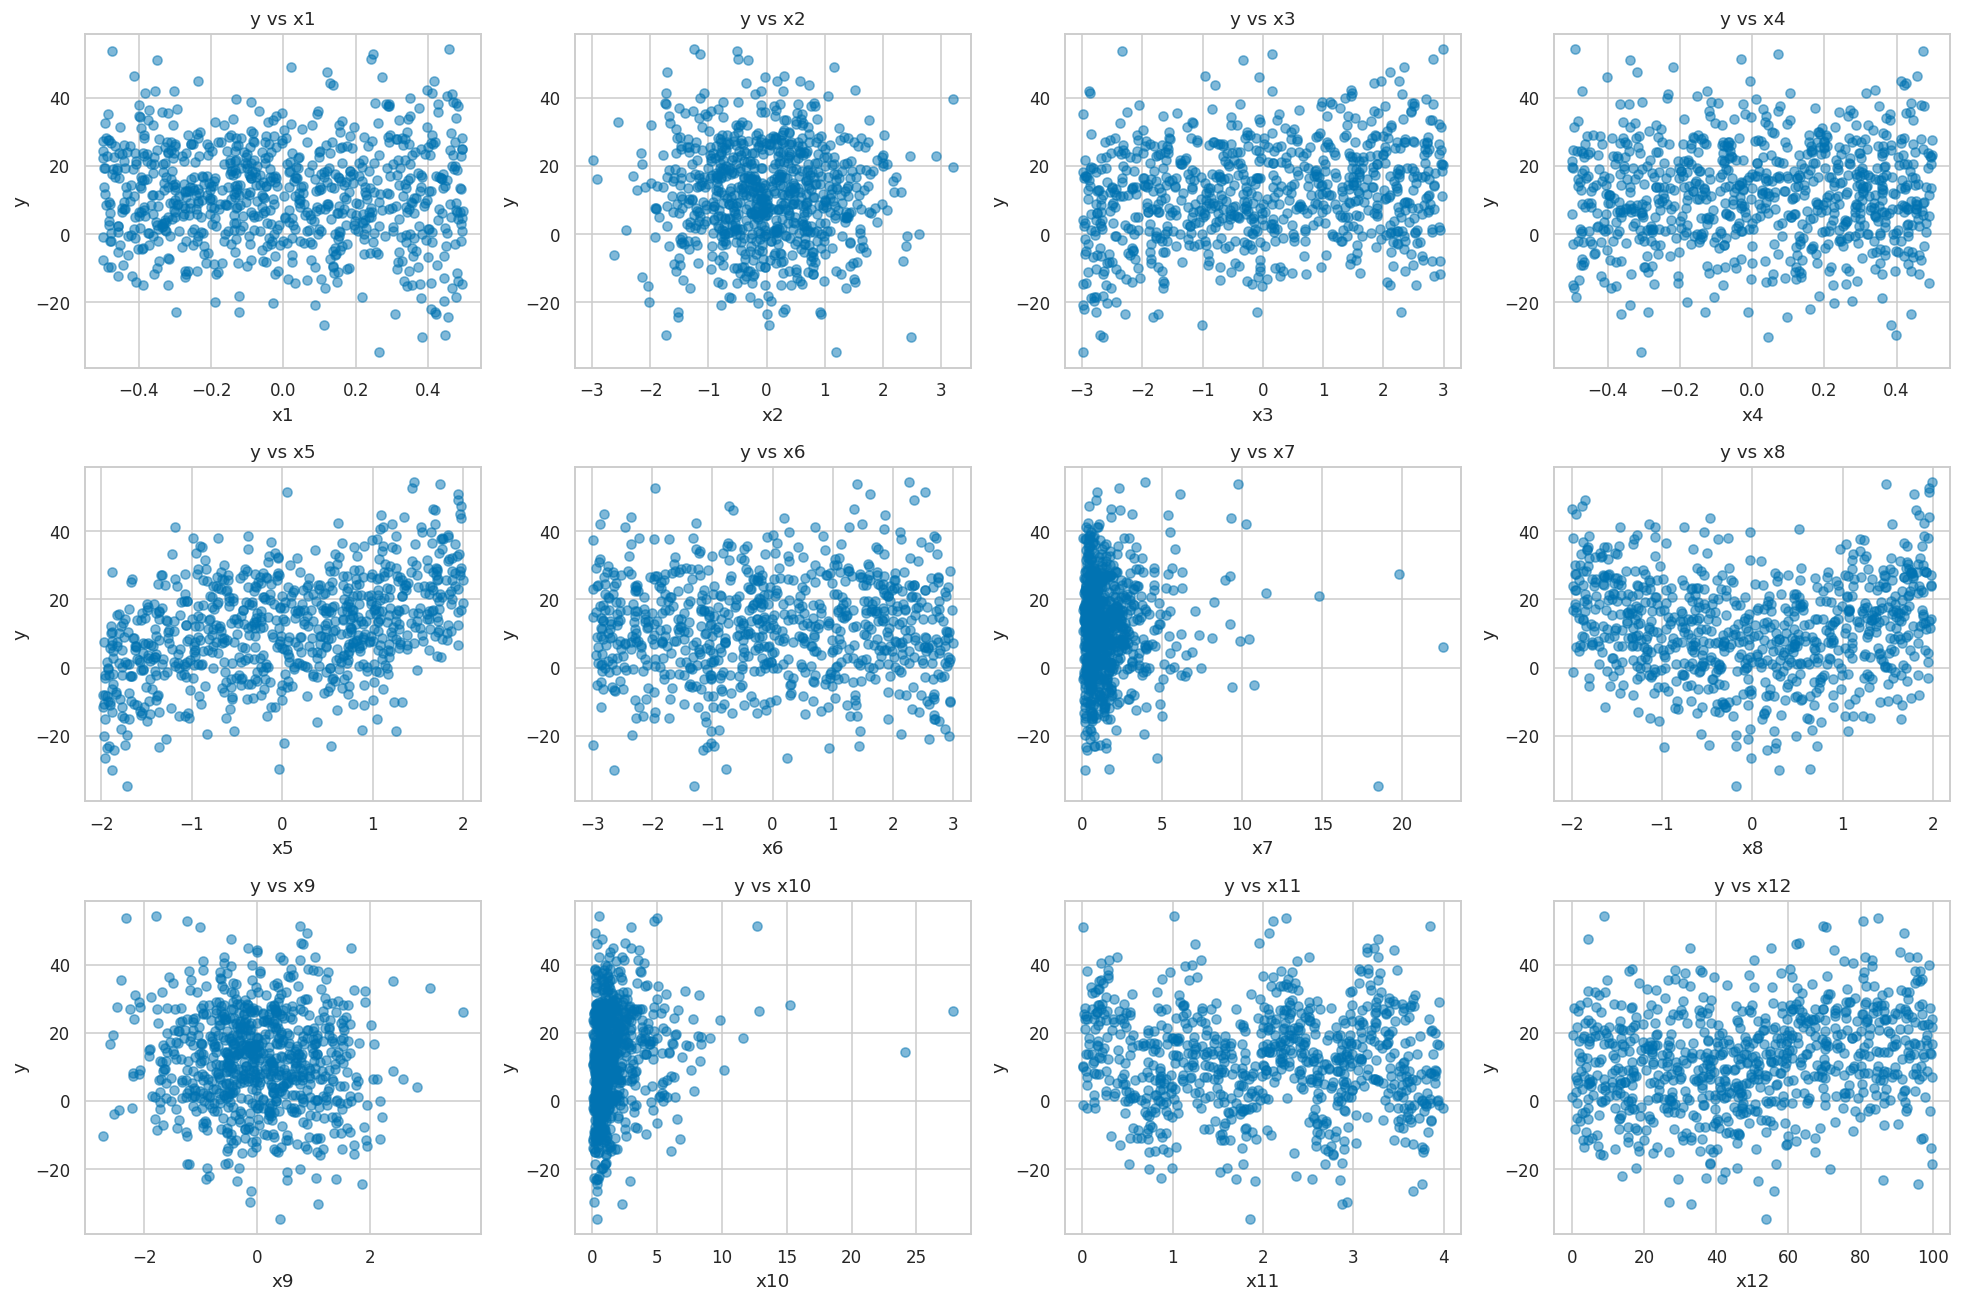

In [7]:
# TODO: `y` contra cada variable. Una rejilla de 12 paneles.
# Usen puntos con transparencia (`alpha`): con 800 observaciones se traslapan.

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, var in enumerate(VARIABLES):
    ax = axes[i]
    ax.scatter(train[var], train["y"], alpha=0.5)
    ax.set_title(f"y vs {var}")
    ax.set_xlabel(var)
    ax.set_ylabel("y")

for j in range(len(VARIABLES), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

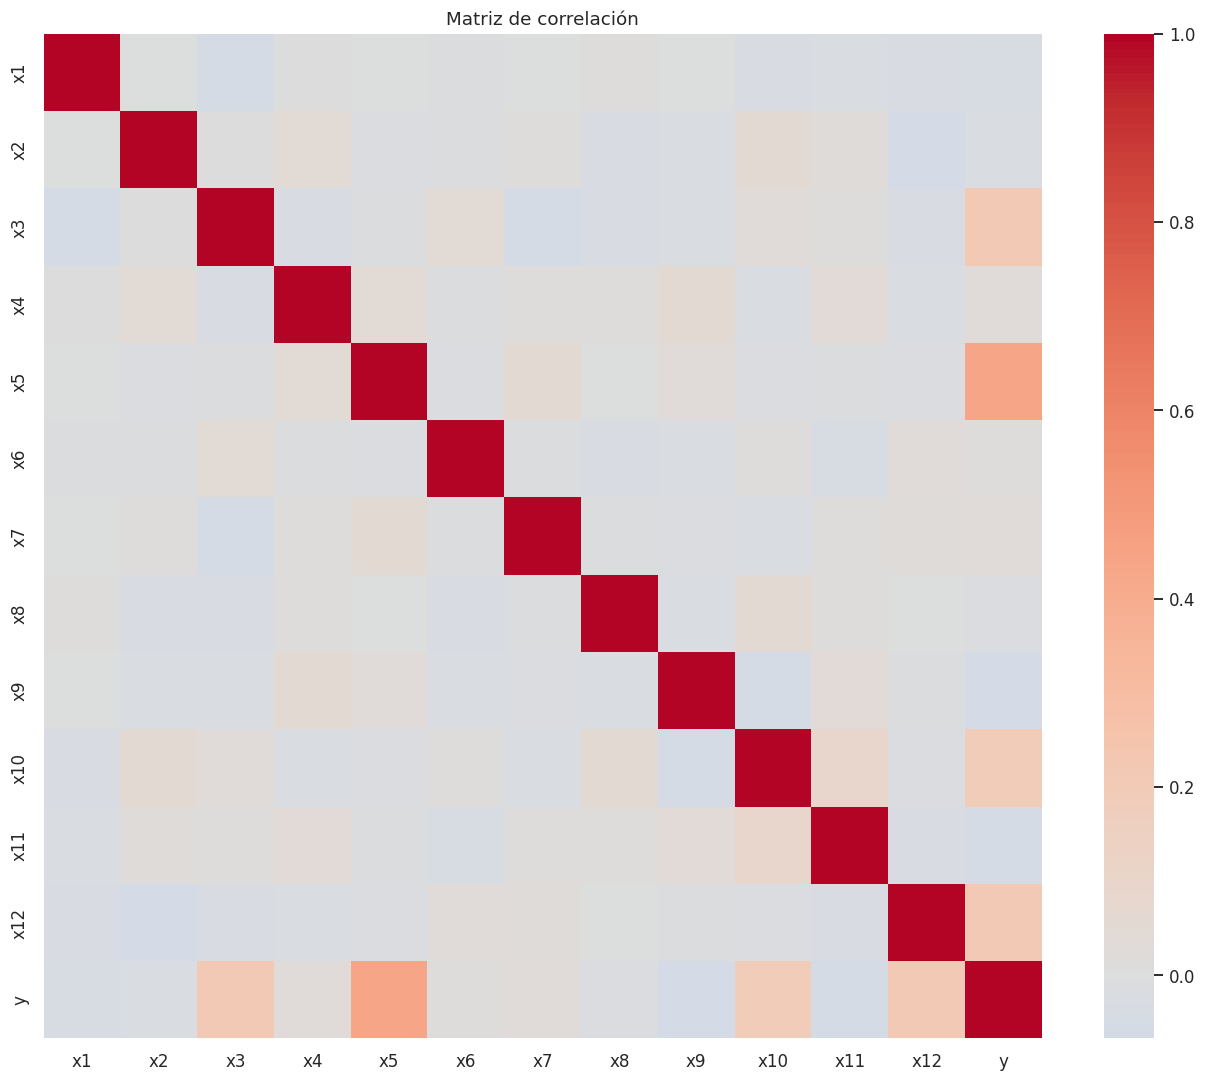

In [8]:
# TODO: matriz de correlación entre las 12 variables y `y`.
corr = train[VARIABLES + ["y"]].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

### 1.1 Registren sus sospechas ahora

Llenen esta tabla **antes** de seguir. Va a ser incómoda de llenar y eso es intencional:
la parte que enseña es volver a leerla al final y ver en qué se equivocaron.

| Variable | ¿Qué sospecho? | ¿En qué gráfica lo vi? | ¿Qué tan seguro estoy? |
|---|---|---|---|
| `x1` | | | |
| `x2` | | | |
| `x3` | | | |
| `x4` | | | |
| `x5` | | | |
| `x6` | | | |
| `x7` | | | |
| `x8` | | | |
| `x9` | | | |
| `x10` | | | |
| `x11` | | | |
| `x12` | | | |

---
## Parte 2. La escalera de residuales

Este es el método central de la tarea, y el que quiero que se lleven de por vida.

Un **residual** es lo que su modelo no logró explicar: `residual = y - ŷ`. Si su modelo
capturó todo lo que había, los residuales deben ser **ruido**: sin forma, sin patrón, sin
estructura. Si al graficar los residuales contra una variable se ve una *forma*, esa
forma es un pedazo de la función que les falta — y la forma les dice qué término agregar.

El ciclo es siempre el mismo:

1. Ajustan el modelo que tienen.
2. Grafican los residuales contra **cada** variable.
3. Si alguna gráfica tiene forma, agregan un término que capture esa forma.
4. Vuelven al paso 1.

Paran cuando ya ninguna gráfica tiene forma, o cuando el MSE deja de bajar.

### ¿Y qué término agrego?

Eso es exactamente lo que tienen que descubrir, y es el trabajo de la tarea.

Lo que sí les conviene es pedirle a su IA el **catálogo**: "¿qué transformaciones existen
para linealizar una relación no lineal?", "¿cómo se modela un efecto que cambia de golpe
a partir de cierto valor?". Eso es conocimiento general y la IA lo tiene completo.

Cuál de esas transformaciones aplica, a cuál de sus doce variables y con qué parámetro,
no se lo puede decir nadie: solo su gráfica. Ahí es donde se aprende.

In [9]:
def ajusta(columnas_extra=None):
    """Ajusta una lineal con las 12 crudas más las columnas derivadas que le pasen.

    `columnas_extra` es un dict {nombre: función que recibe un DataFrame y devuelve
    una Serie}. Así el mismo término se construye igual en train, validación y test,
    que es donde se equivoca todo el mundo.

    Devuelve (modelo, mse_validacion, residuales_de_validacion, constructor).
    """
    columnas_extra = columnas_extra or {}

    def construye(df):
        salida = df[VARIABLES].copy()
        for nombre, f in columnas_extra.items():
            salida[nombre] = f(df)
        return salida

    modelo = LinearRegression().fit(construye(X_train), y_train)
    pred_val = modelo.predict(construye(X_val))
    mse = mean_squared_error(y_val, pred_val)
    return modelo, mse, y_val - pred_val, construye


modelo, mse, residuales, _ = ajusta()
print(f"Modelo con las 12 crudas -> MSE de validación {mse:.2f}")

Modelo con las 12 crudas -> MSE de validación 141.23


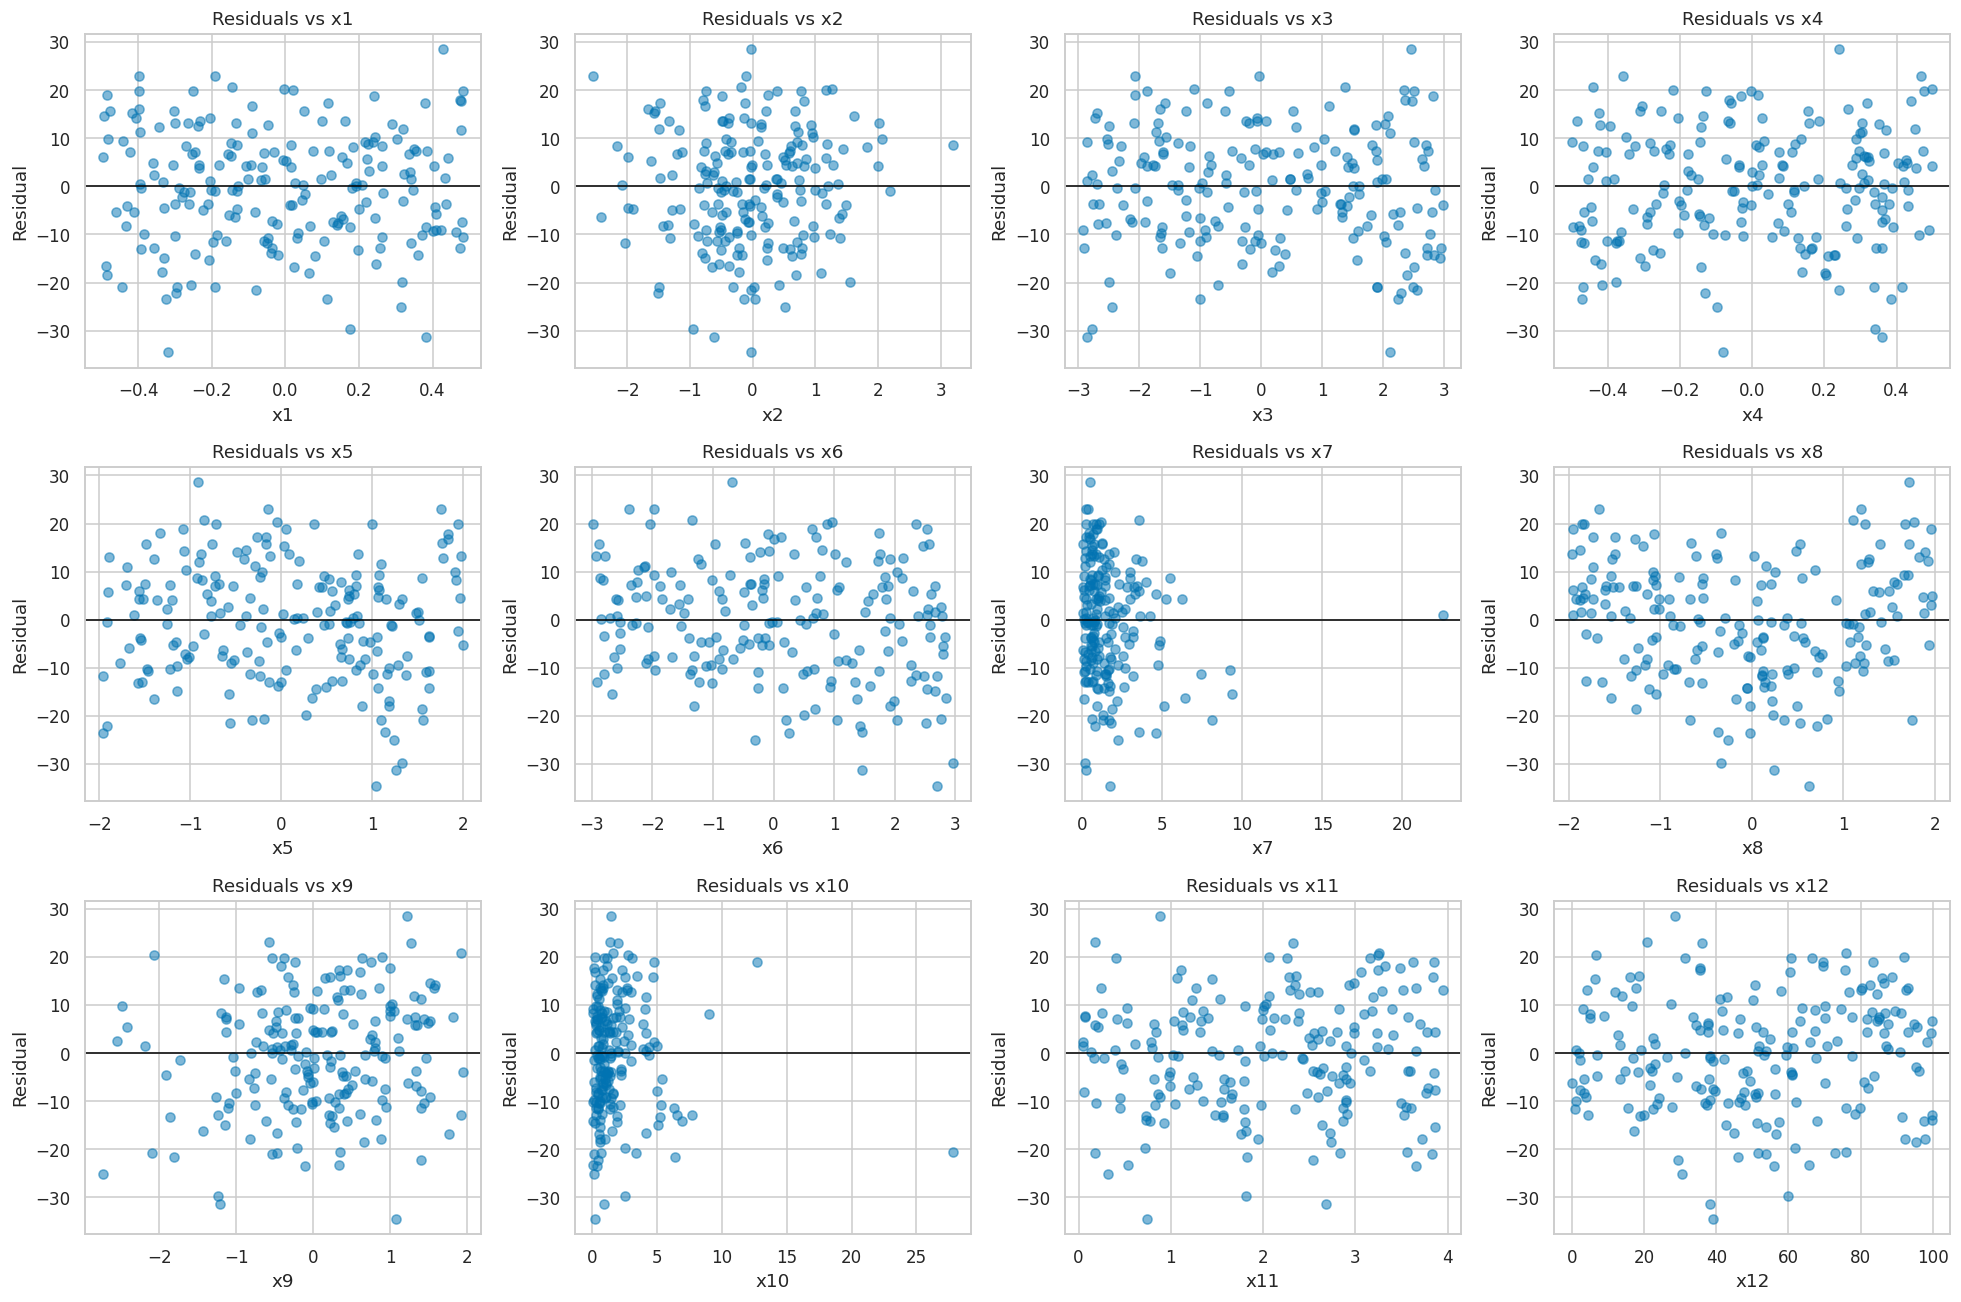

In [10]:
# TODO: grafiquen los residuales contra cada una de las 12 variables.
# Una rejilla de 12 paneles, y en cada uno una línea horizontal en 0 como referencia.
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, var in enumerate(VARIABLES):
    ax = axes[i]
    ax.scatter(X_val[var], residuales, alpha=0.5)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"Residuals vs {var}")
    ax.set_xlabel(var)
    ax.set_ylabel("Residual")

for j in range(len(VARIABLES), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()
# Lo que buscan es FORMA, no dispersión. Una nube gruesa sin patrón está bien;
# una nube que sube, baja, ondula o salta es un término que les falta.

MSE modelo ajustado: 56.4342


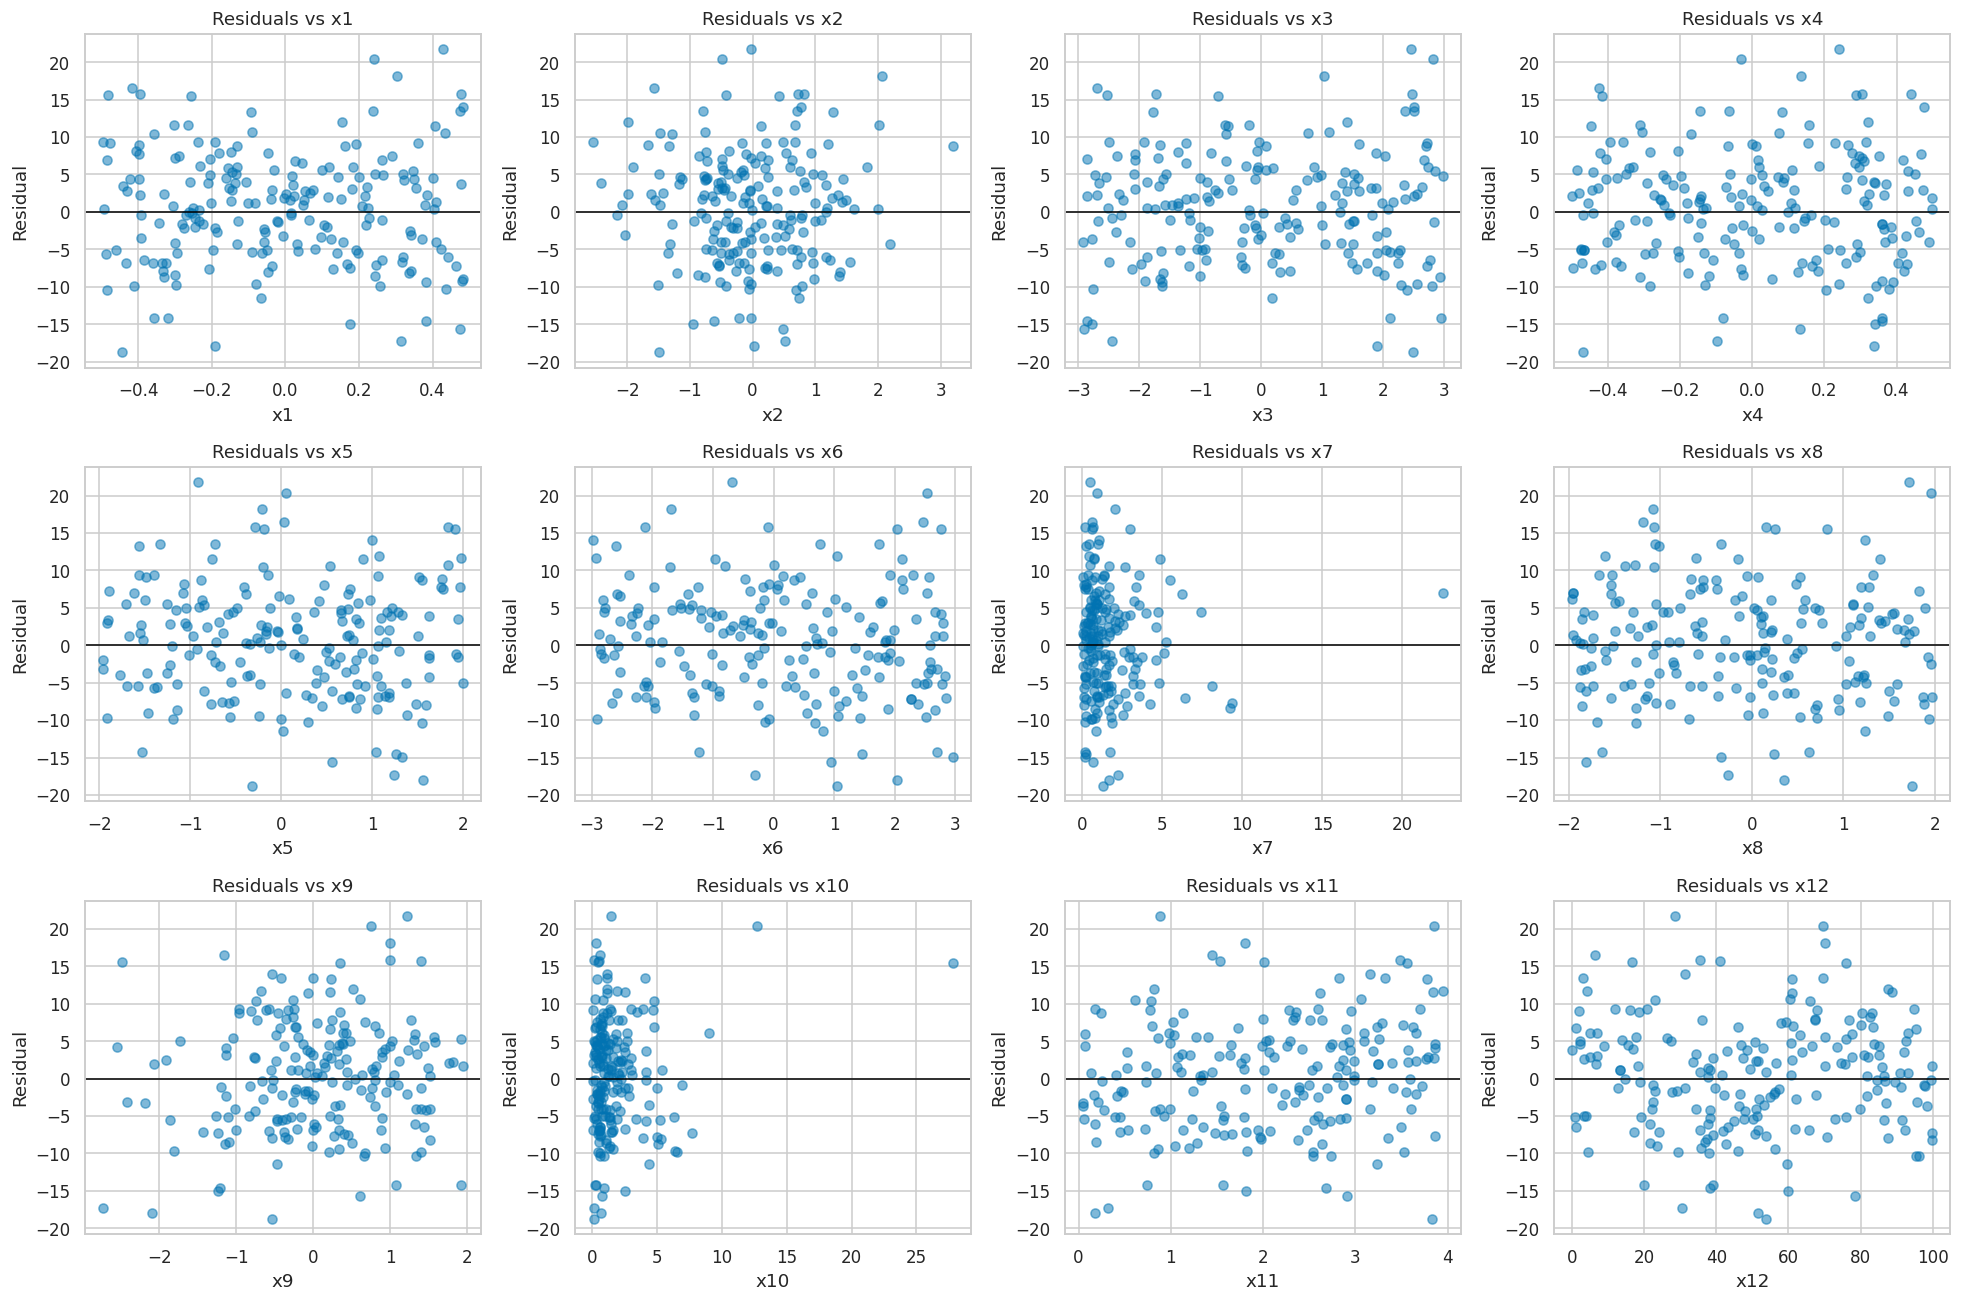

In [11]:
# TODO: agreguen su primer término y vuelvan a medir.
# Prueben una sola transformación a la vez para saber si realmente ayudó.
extras = {
    "x8_cuadrado": lambda d: d["x8"] ** 2,
    "x5_cubico": lambda d: d["x5"] ** 3,
    "x11_seno": lambda d: np.sin(2 * np.pi * d["x11"]),
    "x10_log": lambda d: np.log1p(d["x10"]),
}

modelo, mse, residuales_ajustado, _ = ajusta(extras)

print(f"MSE modelo ajustado: {mse:.4f}")

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, var in enumerate(VARIABLES):
    ax = axes[i]
    ax.scatter(X_val[var], residuales_ajustado, alpha=0.5)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"Residuals vs {var}")
    ax.set_xlabel(var)
    ax.set_ylabel("Residual")

plt.tight_layout()
plt.show()


In [12]:
# TODO: repitan el ciclo. Agreguen términos de uno en uno, graficando los residuales
# cada vez, hasta que ninguna gráfica tenga forma.
#
# Vayan guardando el MSE de cada paso: la bitácora de la Parte 5 lo pide.

---
## Parte 3. Lo que las gráficas de una variable no pueden ver

Cuando terminen la Parte 2 van a tener un modelo decente y, probablemente, ninguna
gráfica de residuales con forma evidente. Eso **no** significa que ya acabaron.

Hay efectos que son invisibles para cualquier gráfica de una sola variable: pueden tener
correlación cero con `y`, scatter plano y residual sin estructura, y aun así ser de los
efectos más grandes del modelo. Ninguna herramienta de la Parte 2 los encuentra.

Su trabajo aquí es averiguar **qué clase de efectos son, cómo se detectan, y si sus datos
tienen alguno**. Su IA les puede explicar la teoría si le hacen la pregunta correcta; sus
datos son los únicos que pueden contestar si aplica.

Una pista de método y ninguna de contenido: si mirar una variable a la vez no basta,
prueben mirando dos a la vez.

Top 10 interacciones:
x1 × x3: 0.480
x6 × x8: -0.188
x2 × x3: 0.175
x9 × x10: 0.171
x6 × x12: -0.165
x6 × x10: -0.158
x9 × x12: 0.152
x7 × x11: -0.129
x4 × x8: 0.121
x1 × x8: 0.117


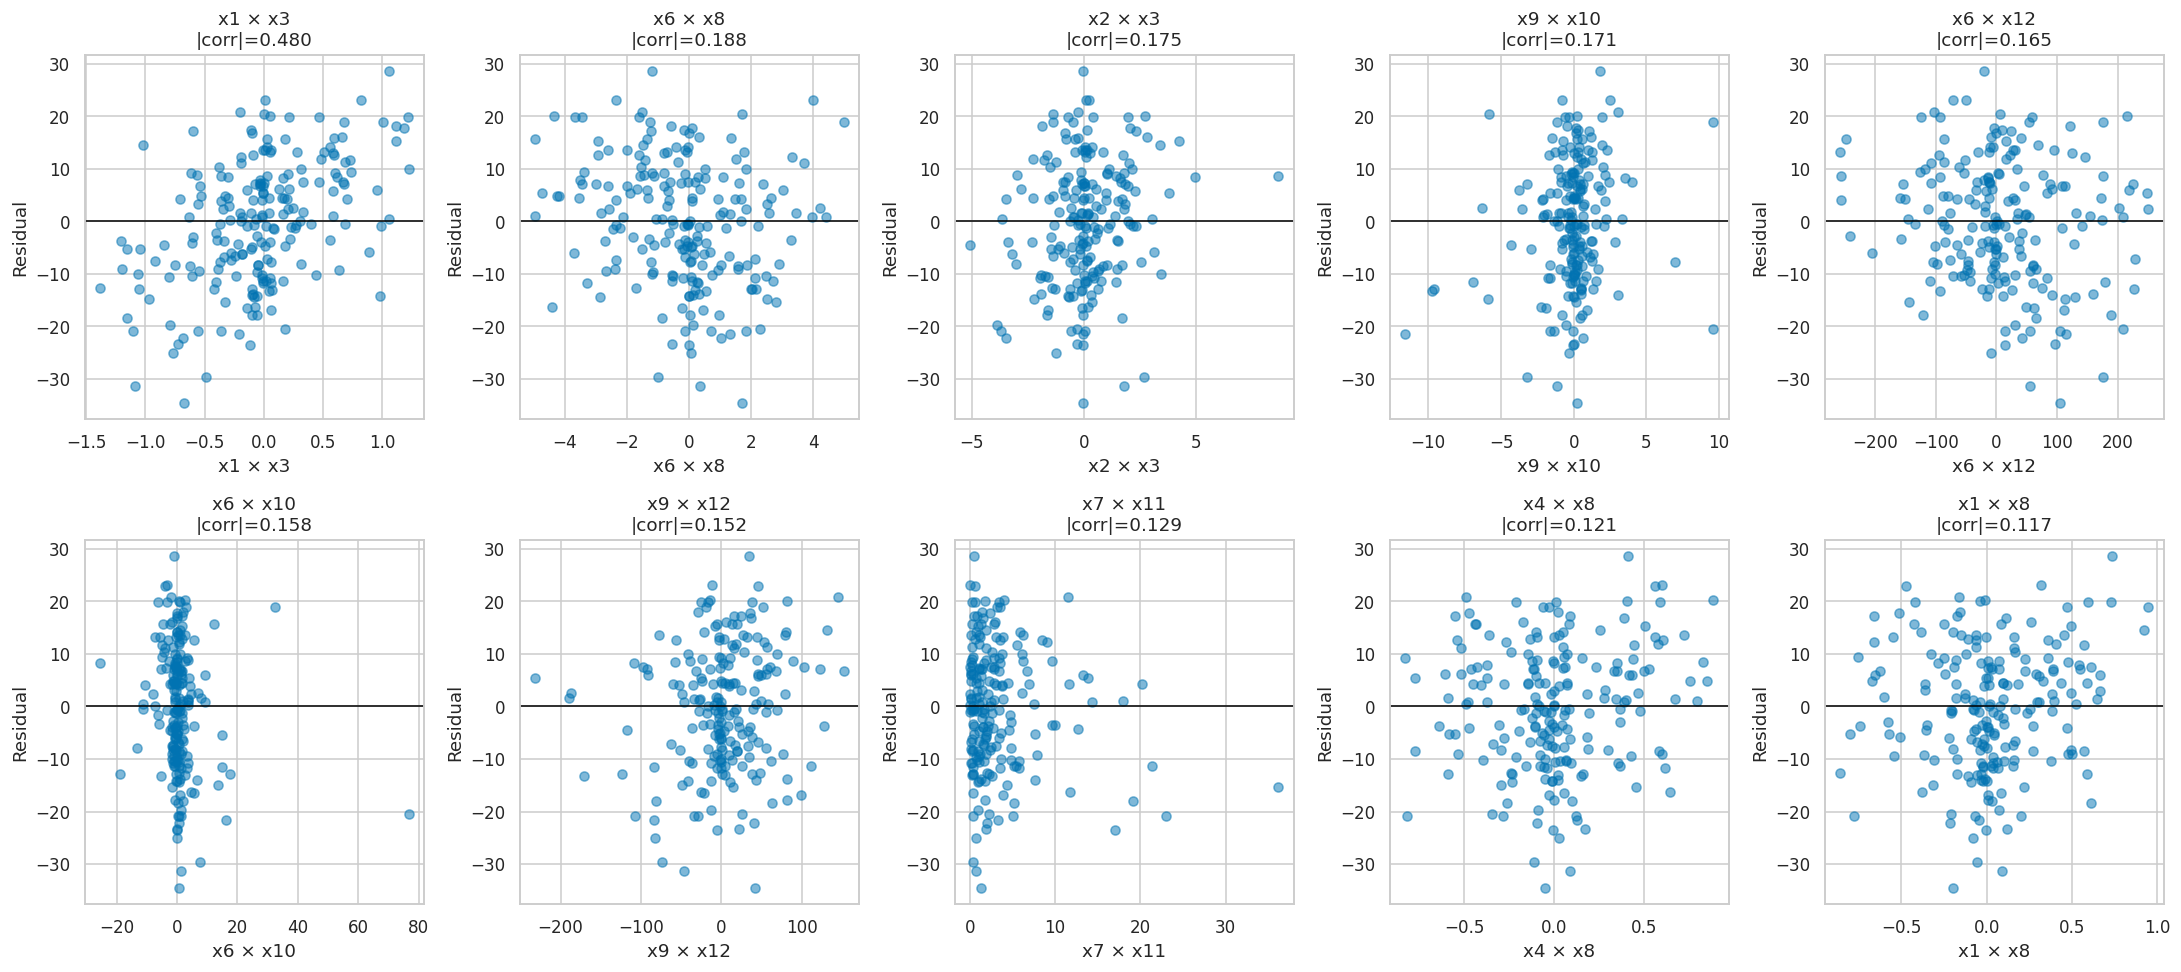

In [16]:
resultados_interacciones = []

for i in range(len(VARIABLES)):
    for j in range(i + 1, len(VARIABLES)):
        var1 = VARIABLES[i]
        var2 = VARIABLES[j]

        producto = X_val[var1] * X_val[var2]
        corr = np.corrcoef(producto, residuales)[0, 1]

        resultados_interacciones.append((var1, var2, corr))

# Ordenar por correlación absoluta, de mayor a menor
resultados_interacciones.sort(key=lambda x: abs(x[2]), reverse=True)

# Mostrar las 10 más prometedoras
print("Top 10 interacciones:")
for var1, var2, corr in resultados_interacciones[:10]:
    print(f"{var1} × {var2}: {corr:.3f}")

# Graficar las top 10
top10 = resultados_interacciones[:10]

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
axes = axes.flatten()

for ax, (var1, var2, corr) in zip(axes, top10):
    producto = X_val[var1] * X_val[var2]
    ax.scatter(producto, residuales, alpha=0.5)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"{var1} × {var2}\n|corr|={abs(corr):.3f}")
    ax.set_xlabel(f"{var1} × {var2}")
    ax.set_ylabel("Residual")

# Ocultar ejes vacíos si faltan paneles
for ax in axes[len(top10):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

MSE con termino actual: 29.3444
Top 10 interacciones:
x4 × x10: -0.244
x9 × x10: 0.219
x4 × x5: -0.177
x6 × x10: 0.158
x10 × x11: 0.157
x5 × x10: -0.155
x9 × x12: 0.154
x6 × x9: 0.153
x1 × x9: 0.144
x10 × x12: 0.142


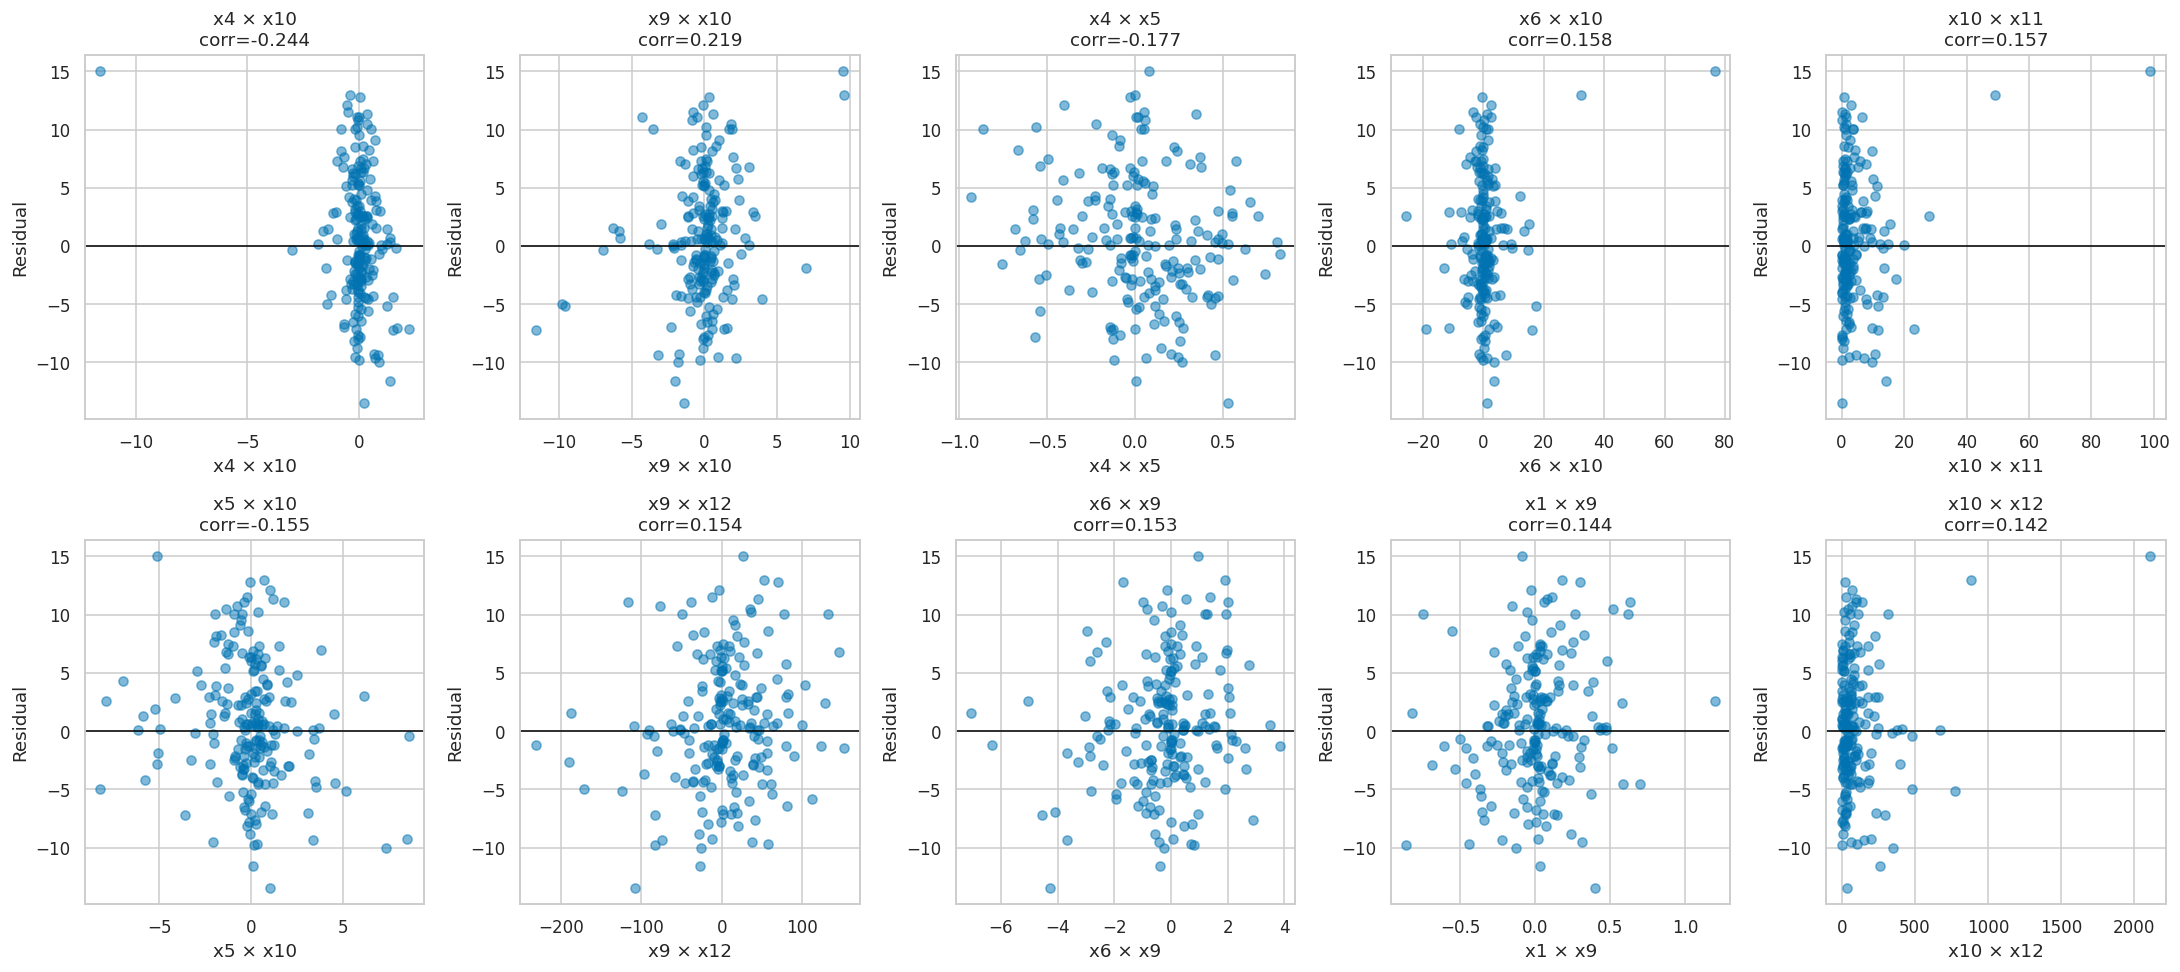

In [ ]:
extras = {
    "x8_cuadrado": lambda d: d["x8"] ** 2,
    "x5_cubico": lambda d: d["x5"] ** 3,
    "x11_seno": lambda d: np.sin(2 * np.pi * d["x11"]),
    "x10_log": lambda d: np.log1p(d["x10"]),
    "x1_x3": lambda d: d["x1"] * d["x3"],
}

modelo_actual, mse_actual, residuales_actual, _ = ajusta(extras)

print(f"MSE con termino actual: {mse_actual:.4f}")

resultados_interacciones = []

for i in range(len(VARIABLES)):
    for j in range(i + 1, len(VARIABLES)):
        var1 = VARIABLES[i]
        var2 = VARIABLES[j]

        producto = X_val[var1] * X_val[var2]
        corr = np.corrcoef(producto, residuales_actual)[0, 1]

        resultados_interacciones.append((var1, var2, corr))

resultados_interacciones.sort(key=lambda x: abs(x[2]), reverse=True)

print("Top 10 interacciones:")
for var1, var2, corr in resultados_interacciones[:10]:
    print(f"{var1} × {var2}: {corr:.3f}")

top10 = resultados_interacciones[:10]

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
axes = axes.flatten()

for ax, (var1, var2, corr) in zip(axes, top10):
    producto = X_val[var1] * X_val[var2]
    ax.scatter(producto, residuales_actual, alpha=0.5)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"{var1} × {var2}\ncorr={corr:.3f}")
    ax.set_xlabel(f"{var1} × {var2}")
    ax.set_ylabel("Residual")

for ax in axes[len(top10):]:
    ax.axis("off")

plt.tight_layout()
plt.show()



---
## Parte 4. El otro camino: fuerza bruta

Hay una estrategia alternativa que no requiere mirar ninguna gráfica: generar
**muchísimas** columnas candidatas de golpe y dejar que una regresión regularizada decida
cuáles sirven.

`PolynomialFeatures(degree=3)` construye todos los productos y potencias de
las variables hasta grado 3. Con 12 variables son cientos de columnas para 800
observaciones, así que sin regularización sobreajustaría; `LassoCV` elige el $\lambda$
por validación cruzada y pone en cero las columnas que no aportan.

Impleméntenlo y **compárenlo contra su modelo de la Parte 3**.

In [23]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

# Camino B: fuerza bruta con términos polinomiales hasta grado 3
modelo_lasso = Pipeline([
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaler", StandardScaler()),
    ("lasso", LassoCV(cv=5, max_iter=100000))
])

# Entrenar solo con train
modelo_lasso.fit(X_train[VARIABLES], y_train)

# Predecir en validación
pred_lasso = modelo_lasso.predict(X_val[VARIABLES])

# MSE de validación
mse_lasso = mean_squared_error(y_val, pred_lasso)

# Cuántas columnas dejó distintas de cero
lasso = modelo_lasso.named_steps["lasso"]
coeficientes = lasso.coef_

n_no_cero = np.sum(coeficientes != 0)

print(f"MSE de validación: {mse_lasso:.4f}")
print(f"Columnas distintas de cero: {n_no_cero}")

MSE de validación: 70.1541
Columnas distintas de cero: 35


In [24]:
poly = modelo_lasso.named_steps["poly"]
lasso = modelo_lasso.named_steps["lasso"]

nombres = poly.get_feature_names_out(VARIABLES)
coeficientes = lasso.coef_

seleccionadas = [
    (nombre, coef)
    for nombre, coef in zip(nombres, coeficientes)
    if coef != 0
]

seleccionadas.sort(key=lambda x: abs(x[1]), reverse=True)

for nombre, coef in seleccionadas:
    print(f"{nombre}: {coef:.4f}")

x5^3: 6.3649
x1 x3: 5.2392
x8^2: 5.0721
x12^2: 2.0558
x3: 1.5495
x10: 1.3861
x10 x12^2: 1.1928
x3 x6^2: 0.7022
x3^3: 0.4383
x6^2 x9: -0.3508
x5 x8 x12: 0.3282
x3 x12^2: 0.3241
x1^2 x5: 0.3205
x2 x9 x10: -0.2897
x5 x10 x12: 0.2864
x11^3: -0.2562
x4^2 x5: 0.2093
x4 x6 x12: -0.1996
x3 x7: 0.1962
x8^2 x12: 0.1957
x2 x5 x9: 0.1146
x2 x3 x10: 0.1139
x4 x10 x12: 0.1131
x1 x6 x11: 0.0806
x5^2 x9: -0.0762
x7 x10 x12: 0.0572
x7 x9: -0.0567
x3 x8 x10: -0.0552
x3 x6 x11: -0.0541
x4^2 x11: -0.0349
x5 x7 x12: 0.0303
x3 x12: 0.0238
x1 x4 x5: 0.0153
x3 x4 x7: -0.0139
x2 x5 x7: 0.0028


In [ ]:
#Probar output de Lasso en mi modelo
extras = {
    "x8_cuadrado": lambda d: d["x8"] ** 2,
    "x5_cubico": lambda d: d["x5"] ** 3,
    "x11_seno": lambda d: np.sin(2 * np.pi * d["x11"]),
    "x10_log": lambda d: np.log1p(d["x10"]),
    "x1_x3": lambda d: d["x1"] * d["x3"],
    "x12_cuadrado": lambda d: d["x12"] ** 2,
}

modelo_actual, mse_actual, residuales_actual, _ = ajusta(extras)

print(f"MSE modelo híbrido con x12^2: {mse_actual:.4f}")

MSE modelo híbrido con x12^2: 28.0621


### 4.1 La pregunta que vale la respuesta

Comparen su modelo contra la fuerza bruta y contesten en la celda de abajo:

1. ¿Cuál dio menor MSE de validación?

El modelo guiado por gráficas obtuvo el menor MSE de validación. Mi modelo de la Parte 3 obtuvo un MSE de 29.3664, mientras que el modelo de fuerza bruta 70.1541, con 35 columnas.

2. Si su modelo guiado por gráficas le ganó a la fuerza bruta: **¿por qué?** Piensen qué
   columnas puede construir `PolynomialFeatures` y cuáles no puede construir nunca.

El modelo guiado por gráficas tuvo mejor desempeño porque pude identificar formas funcionales que PolynomialFeatures no puede construir. No puede generar transformaciones como senos o logaritmos, que encontré al analizar las gráficas de residuales.

3. Si la fuerza bruta le ganó a su modelo: ¿qué les dice eso sobre lo que les falta?

En mi caso la fuerza bruta no superó al modelo guiado, pero creo que hubiera significado que no se analizaron bien las gráficas y que faltó encontrar relaciones importantes. 

4. ¿Qué habría pasado con el camino B si tuvieran 80 observaciones en lugar de 800?

Con 80 observaciones, el camino B tendría más problemas de sobreajuste, porque estaría probando muchas columnas con muy pocos datos. Aunque Lasso ayuda a eliminar las que no sirven, tendría menos información para identificar cuáles realmente aportan al modelo.


---
## Parte 5. Bitácora

Esta parte vale tanto como el MSE. Una fila por hipótesis, **incluidas las que
fallaron** — sobre todo las que fallaron.

Si no tienen al menos un callejón sin salida documentado, esta parte vale cero: significa
que no exploraron, o que le pidieron la respuesta a alguien.

| # | Hipótesis | Gráfica que la probó | Término agregado | MSE antes → después | ¿La sugirió la IA o yo? |
|---|---|---|---|---|---|
| 1 | | | | | |
| 2 | | | | | |
| 3 | | | | | |
| 4 | | | | | |
| 5 | | | | | |
| 6 | | | | | |
| 7 | | | | | |
| 8 | | | | | |

### 5.1 Su modelo final, en palabras

Escriban la función que creen que genera los datos. Algo de la forma
`y = a + b*x? + c*f(x?) + ... + ruido`, con los nombres de sus variables.

*(Su respuesta aquí)*

### 5.2 Dónde se equivocó su IA

Cuenten **un** momento concreto en el que la IA les dijo algo que resultó falso o
inútil para sus datos, y cómo lo detectaron. Si dicen que nunca falló, es que no la
interrogaron lo suficiente.

*(Su respuesta aquí)*

### 5.3 Cuándo pararon y por qué

`/validar` les dice cuál es el MSE meta: el error del modelo bien especificado, que es
**ruido puro** y no se puede bajar. ¿Qué tan cerca quedaron? ¿Cómo supieron que ya no
valía la pena seguir?

*(Su respuesta aquí)*

---
## Entrega

Corran la celda de abajo: ajusta **su modelo final** usando *todo* `train` (ya no solo la
partición de entrenamiento — con más datos, mejores coeficientes) y escribe el archivo de
predicciones en el lugar exacto donde el bot lo busca.

In [28]:
# TODO: pongan aquí las columnas derivadas de su modelo final, con el mismo formato
# que usaron en `ajusta`. Si su modelo final es el baseline crudo, déjenlo vacío.
MI_MODELO = {
    "x8_cuadrado": lambda d: d["x8"] ** 2,
    "x5_cubico": lambda d: d["x5"] ** 3,
    "x11_seno": lambda d: np.sin(2 * np.pi * d["x11"]),
    "x10_log": lambda d: np.log1p(d["x10"]),
    "x1_x3": lambda d: d["x1"] * d["x3"],
    "x12_cuadrado": lambda d: d["x12"] ** 2,
}


def construye_final(df):
    salida = df[VARIABLES].copy()
    for nombre, f in MI_MODELO.items():
        salida[nombre] = f(df)
    return salida


# La estimación honesta de su MSE: ajustada SOLO en la partición de entrenamiento
# y medida en validación. Este es el número que deberían creer.
_, mse_estimado, _, _ = ajusta(MI_MODELO)
print(f"MSE estimado (ajustado en train, medido en validación): {mse_estimado:.2f}")

# Y ahora sí, el modelo que entregan: reajustado con TODO train, porque con 800
# observaciones en lugar de 600 los coeficientes salen mejores. Ojo: a este modelo
# ya no se le puede medir el MSE en validación, porque validación fue parte de su
# entrenamiento. Medirlo ahí daría un número optimista y falso.
modelo_final = LinearRegression().fit(construye_final(train), train["y"])
predicciones = modelo_final.predict(construye_final(test))

assert len(predicciones) == 400, f"deben ser 400 predicciones, hay {len(predicciones)}"
assert np.isfinite(predicciones).all(), "hay predicciones NaN o infinitas"

destino = RAIZ / "entregas/tarea-01" / CARPETA
destino.mkdir(parents=True, exist_ok=True)
pd.DataFrame({"y": predicciones}).to_csv(destino / "predicciones.csv", index=False)

print(f"\nEscrito: {destino.relative_to(RAIZ)}/predicciones.csv")
print(f"{len(predicciones)} predicciones, rango {predicciones.min():.2f} a {predicciones.max():.2f}")

MSE estimado (ajustado en train, medido en validación): 28.06

Escrito: entregas/tarea-01/vdd692efc/predicciones.csv
400 predicciones, rango -27.75 a 50.92


### Los últimos pasos

El detalle está en **`tareas/tarea_01_README.md`**, que trae dos caminos: hacer todo en
**GitHub Codespaces** (en el navegador, sin instalar nada) o en **su computadora**. Los
dos son válidos; si nunca han configurado Python, vayan por Codespaces.

En resumen, igual en los dos casos:

1. Hagan commit de este notebook **y** de su `predicciones.csv`.
2. `git push` a su rama en su fork.
3. Abran un Pull Request al repo del curso.
4. Comenten **`/validar`** en el PR. Les confirma el formato y les dice su MSE objetivo,
   sin gastar intento. Úsenlo siempre antes de calificar.
5. Cuando estén listos, comenten **`/calificar`**. Eso sí gasta uno de sus 3 intentos.

Si `/validar` les marca un error, corrijan, hagan push otra vez y vuelvan a comentar
`/validar`. Las veces que quieran.